# HW2 : Cross-Validation and  Regularization

### Configuration and imports


In [66]:
import os
import numpy as np
import pandas as pd
 
import sklearn.preprocessing
import sklearn.pipeline
import sklearn.linear_model
import sklearn.metrics
import sklearn.model_selection


In [67]:
from matplotlib import pyplot as plt

import seaborn as sns
#This sets the default style for all figures. 
sns.set('notebook', font_scale=1.25, style='whitegrid')

You may need to adjust your data directory to point towards the auto data. Please do not adjust the random seed for the version of your results you turn in.  

In [68]:
SEED = 12345 

DATA_DIR = 'data_auto/'

## Helper Functions

Here we provide some functions you may find useful for your analysis. You are not **required** to use these helper functions, but you may find them useful.

### Data Loading 

In [69]:
def load_2d_arr_from_csv(fname, include_header=False):
    x = np.loadtxt(os.path.join(DATA_DIR, fname), delimiter=',', skiprows=1)
    assert x.ndim == 2
    if include_header:
        header_cols = np.loadtxt(os.path.join(DATA_DIR, fname), delimiter=',', dtype=str)[0].tolist()
        return x, header_cols
    else:
        return x
    
def load_1d_arr_from_csv(fname):
    x = np.loadtxt(os.path.join(DATA_DIR, fname), delimiter=',', skiprows=1)
    if x.ndim == 1:
        return x
    else:
        raise ValueError("Not 1d")

These functions can then be used as follows.

In [70]:
x_tr_MF, xcolnames_F = load_2d_arr_from_csv('x_train.csv', include_header=True)
x_va_NF = load_2d_arr_from_csv('x_valid.csv')
x_te_PF = load_2d_arr_from_csv('x_test.csv')

y_tr_M = load_1d_arr_from_csv('y_train.csv')
y_va_N = load_1d_arr_from_csv('y_valid.csv')
y_te_P = load_1d_arr_from_csv('y_test.csv')

print(xcolnames_F)
print(x_tr_MF[:5])
print(y_tr_M[:5,np.newaxis])

['horsepower', 'weight', 'cylinders', 'displacement']
[[ 115. 2595.    6.  173.]
 [ 180. 4380.    8.  350.]
 [ 150. 4457.    8.  318.]
 [ 105. 3897.    6.  250.]
 [ 193. 4732.    8.  304.]]
[[28.8]
 [16.5]
 [14. ]
 [16. ]
 [ 9. ]]


## Plotting

In [71]:
def plot_train_and_valid_error_vs_hyper(
        hyper_list, err_tr_list=None, err_va_list=None,
        ymax=40,
        leg_loc='upper right',
        xlabel='polynomial degree',
        ylabel='RMSE'):
    if err_va_list is not None:
        plt.plot(hyper_list, err_va_list, 'rs-', label='valid');
    if err_tr_list is not None:
        plt.plot(hyper_list, err_tr_list, 'bd:', label='train');
    plt.ylim([0, ymax]);
    plt.legend(loc=leg_loc);
    plt.xlabel(xlabel);
    plt.ylabel(ylabel);

## Building a regression pipeline

### Sanitizing output
You should sanitize any model's predictions to help ensure the predicted values that are physically plausible. 
We are predicting MPG, which should 
* (1) always be positive, and
* (2) will probably never exceed 120% of the largest value we see in train data

Predictions should be sanitized before being used to calculate errors or select best-performing models for your report. 

In [72]:
Y_MAX = 60.0 # The max MPG is about 48 in the training set

def sanitize(yhat_N):
    yhat_N = np.maximum(yhat_N, 0)
    yhat_N = np.minimum(yhat_N, Y_MAX)
    return yhat_N

### Creating multiple pipelines

This function returns a scikit-learn `pipeline` that of the specified degree. 
You'll need to make a version that takes in an additional parameter, `alpha` and use `sklearn.linear_model.Ridge` to create ridge polynomial regression pipelines. 

In [73]:
def make_pipeline_unpenalized_linear_regr_with_poly_feats(degree=1):
    pipeline = sklearn.pipeline.Pipeline(
        steps=[
         ('rescaler', sklearn.preprocessing.MinMaxScaler()),
         ('poly_transformer', sklearn.preprocessing.PolynomialFeatures(degree=degree, include_bias=False)),
         ('regr', sklearn.linear_model.LinearRegression())
        ])
    
    # Return the constructed pipeline
    # We can treat it as if it has a 'regression' API
    # e.g. a fit and a predict method
    return pipeline



### Inspecting learned weights

We can access individual steps of the pipeline to extract information, as demonstrated in the blow function.

In [74]:
def pretty_print_learned_weights(pipeline, xcolnames_F):
    ''' Print the learned parameters of given pipeline.
        Note that this function assumes that the pipeline has the named steps "poly_transformer" and "regr"
    '''
    my_lin_regr = pipeline.named_steps['regr']

    feat_names = pipeline.named_steps['poly_transformer'].get_feature_names_out()
    coef_values = my_lin_regr.coef_

    print("intercept: %.2f" % (my_lin_regr.intercept_))
    print("")

    print("%9s   %s" % ("weight", "feature var"))
    for feat, coef in zip(feat_names, coef_values):
        print("% 9.2f * %s" % (coef, feat))
    
    print("where ")
    for ff, colname in enumerate(xcolnames_F):
        print("x%d = %s" % (ff, colname))

# Your Code

Model 0: baseline guess-train-set-mean
- given a training set of size N, compute the mean of all response values y_i, and store that as y_hat
- linear regressor with no input features
- computer the mean of training set y values 


In [75]:
mean_y_train = np.mean(y_tr_M)
print (mean_y_train)

23.48125


Question 1A:
Fit a linear regression model to a polynomial feature transform when degree = 1.

Provide the weight coefficient values (to 2 decimal places) for each of the  features of your degree = 1 model. With these values, which feature has the highest positive impact on MPG? Which has the highest negative impact? Do these make sense?

Hint: Engine displacement refers to the overall volume of air that can move through the engine. Larger engine means larger displacement.



In [76]:
m1_deg1 = make_pipeline__unpenalized_linear_regr_with_poly_feats(degree = 1)
m1_deg1.fit(x_tr_MF, y_tr_M)
pretty_print_learned_weights(m1_deg1, xcolnames_F)

intercept: 34.07

   weight   feature var
   -10.43 * x0
   -18.23 * x1
    -1.15 * x2
     0.58 * x3
where 
x0 = horsepower
x1 = weight
x2 = cylinders
x3 = displacement


Question 1B: 
Fit a linear regression model to a polynomial feature transform when degree = 4.

Provide the weight coefficient values (to 2 decimal places) for each of the  features of your degree = 4 model.

Compare the 1-degree vs. 4-degree learned model parameters. Which model tends to have larger parameters? Why do you think that is?

In [77]:
m1_deg4 = make_pipeline_unpenalized_linear_regr_with_poly_feats(degree = 4)
m1_deg4.fit(x_tr_MF, y_tr_M)
pretty_print_learned_weights(m1_deg4, xcolnames_F)

intercept: -123.11

   weight   feature var
   617.45 * x0
  -191.08 * x1
  1774.24 * x2
 -1343.56 * x3
   159.25 * x0^2
  -323.66 * x0 x1
 -5179.64 * x0 x2
   198.45 * x0 x3
    61.37 * x1^2
  2573.25 * x1 x2
 -1596.95 * x1 x3
 -5943.40 * x2^2
  7359.52 * x2 x3
  2883.15 * x3^2
  -630.58 * x0^3
  1377.51 * x0^2 x1
 -1600.47 * x0^2 x2
  1529.25 * x0^2 x3
  -105.12 * x0 x1^2
 -7880.76 * x0 x1 x2
 12085.95 * x0 x1 x3
 13051.50 * x0 x2^2
  5626.91 * x0 x2 x3
-14222.70 * x0 x3^2
   611.22 * x1^3
 -1478.94 * x1^2 x2
  -359.76 * x1^2 x3
 -7343.55 * x1 x2^2
 17674.97 * x1 x2 x3
-13648.53 * x1 x3^2
  4525.05 * x2^3
    47.94 * x2^2 x3
-34068.88 * x2 x3^2
 20804.11 * x3^3
  -345.94 * x0^4
  1047.47 * x0^3 x1
   133.89 * x0^3 x2
   702.32 * x0^3 x3
  1031.68 * x0^2 x1^2
  3678.25 * x0^2 x1 x2
-11633.91 * x0^2 x1 x3
 -1147.94 * x0^2 x2^2
  1506.00 * x0^2 x2 x3
  3042.21 * x0^2 x3^2
 -5637.55 * x0 x1^3
  3990.55 * x0 x1^2 x2
  7624.03 * x0 x1^2 x3
 12467.48 * x0 x1 x2^2
-36650.46 * x0 x1 x2 x3
 19

Question 2: 
We'll now perform a "complete" experiment for our polynomial regression model and polynomial ridge regression models.

For the polynomial regression model, try all possible degrees from 1 to 7 (inclusive).

In [78]:
print ("m1_d1")
m1_deg1 = make_pipeline__unpenalized_linear_regr_with_poly_feats(degree = 1)
m1_deg1.fit(x_tr_MF, y_tr_M)
pretty_print_learned_weights(m1_deg1, xcolnames_F)

print ("m1_d2")
m1_deg2 = make_pipeline__unpenalized_linear_regr_with_poly_feats(degree = 2)
m1_deg2.fit(x_tr_MF, y_tr_M)
pretty_print_learned_weights(m1_deg2, xcolnames_F)

print ("m1_d3")
m1_deg3 = make_pipeline__unpenalized_linear_regr_with_poly_feats(degree = 3)
m1_deg3.fit(x_tr_MF, y_tr_M)
pretty_print_learned_weights(m1_deg3, xcolnames_F)

print ("m1_d4")
m1_deg4 = make_pipeline__unpenalized_linear_regr_with_poly_feats(degree = 4)
m1_deg4.fit(x_tr_MF, y_tr_M)
pretty_print_learned_weights(m1_deg4, xcolnames_F)

print ("m1_d5")
m1_deg5 = make_pipeline__unpenalized_linear_regr_with_poly_feats(degree = 5)
m1_deg5.fit(x_tr_MF, y_tr_M)
pretty_print_learned_weights(m1_deg5, xcolnames_F)

print ("m1_d6")
m1_deg6 = make_pipeline__unpenalized_linear_regr_with_poly_feats(degree = 6)
m1_deg6.fit(x_tr_MF, y_tr_M)
pretty_print_learned_weights(m1_deg6, xcolnames_F)

print ("m1_d7")
m1_deg7 = make_pipeline__unpenalized_linear_regr_with_poly_feats(degree = 7)
m1_deg7.fit(x_tr_MF, y_tr_M)
pretty_print_learned_weights(m1_deg7, xcolnames_F)

m1_d1
intercept: 34.07

   weight   feature var
   -10.43 * x0
   -18.23 * x1
    -1.15 * x2
     0.58 * x3
where 
x0 = horsepower
x1 = weight
x2 = cylinders
x3 = displacement
m1_d2
intercept: 40.17

   weight   feature var
   -40.72 * x0
    -7.20 * x1
   -11.00 * x2
   -11.10 * x3
    -4.45 * x0^2
     8.80 * x0 x1
    26.38 * x0 x2
     8.98 * x0 x3
   -31.77 * x1^2
    27.17 * x1 x2
    13.43 * x1 x3
    21.76 * x2^2
   -80.86 * x2 x3
    52.65 * x3^2
where 
x0 = horsepower
x1 = weight
x2 = cylinders
x3 = displacement
m1_d3
intercept: 46.63

   weight   feature var
   -51.31 * x0
    -0.19 * x1
   -71.52 * x2
    -1.51 * x3
    -6.50 * x0^2
   -89.63 * x0 x1
   111.51 * x0 x2
   154.55 * x0 x3
   -24.89 * x1^2
   273.68 * x1 x2
  -324.89 * x1 x3
   232.32 * x2^2
  -729.76 * x2 x3
   619.52 * x3^2
   -25.77 * x0^3
  -525.15 * x0^2 x1
   109.24 * x0^2 x2
   533.34 * x0^2 x3
   550.23 * x0 x1^2
  -721.22 * x0 x1 x2
   937.28 * x0 x1 x3
  -108.35 * x0 x2^2
   570.59 * x0 x2 x3
 -1485.1

For the penalized model, fix degree=4. Consider possible alpha values:

alpha_list = np.asarray([1.e-10, 1.e-08, 1.e-06, 1.e-04, 1.e-02, 1.e+00, 1.e+02, 1.e+04, 1.e+06])

In [79]:
def make_pipeline_ridge_regr_with_poly_feats(degree = 4, alpha = 1.0, include_scaler=True):
    pipeline = sklearn.pipeline.Pipeline(
        steps=[
         ('rescaler', sklearn.preprocessing.MinMaxScaler()),
         ('poly_transformer', sklearn.preprocessing.PolynomialFeatures(degree=degree, include_bias=False)),
         ('regr', sklearn.linear_model.Ridge(alpha=alpha, random_state=SEED))
        ])
    
    # Return the constructed pipeline
    # We can treat it as if it has a 'regression' API
    # e.g. a fit and a predict method
    return pipeline

Question 2A:

In [80]:
def calc_rmse(y_true, y_pred):
    return sklearn.metrics.root_mean_squared_error(y_true, sanitize(y_pred))

/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/li

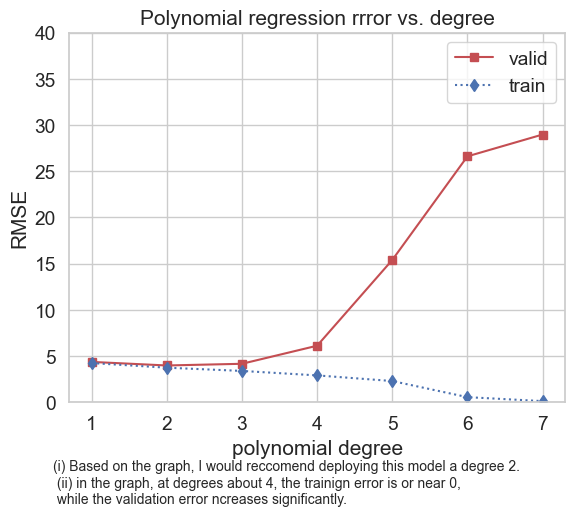

In [81]:
degrees = list(range(1, 8))
err_tr_deg = []
err_va_deg = []

best_val_err_m1 = float('inf')
best_deg_m1 = None
best_m1_pipeline = None

for deg in degrees:
    pipe = make_pipeline_unpenalized_linear_regr_with_poly_feats(degree=deg)
    pipe.fit(x_tr_MF, y_tr_M)
    
    tr_err = calc_rmse(y_tr_M, pipe.predict(x_tr_MF))
    va_err = calc_rmse(y_va_N, pipe.predict(x_va_NF))
    
    err_tr_deg.append(tr_err)
    err_va_deg.append(va_err)
    
    # updating to the best degree value 
    if va_err < best_val_err_m1:
        best_val_err_m1 = va_err
        best_deg_m1 = deg
        best_m1_pipeline = pipe

err_m1_tr = calc_rmse(y_tr_M, best_m1_pipeline.predict(x_tr_MF))
err_m1_va = calc_rmse(y_va_N, best_m1_pipeline.predict(x_va_NF))
err_m1_te = calc_rmse(y_te_P, best_m1_pipeline.predict(x_te_PF))

plt.figure()
plot_train_and_valid_error_vs_hyper(degrees, err_tr_deg, err_va_deg, ymax=40, xlabel='polynomial degree')
plt.title('Polynomial regression rrror vs. degree')
plt.figtext(0.1,-0.1, "(i) Based on the graph, I would reccomend deploying this model a degree 2. \n (ii) in the graph, at degrees about 4, the trainign error is or near 0, \n while the validation error ncreases significantly.", fontsize = 10)
plt.show()

Question 2B:

/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  retur

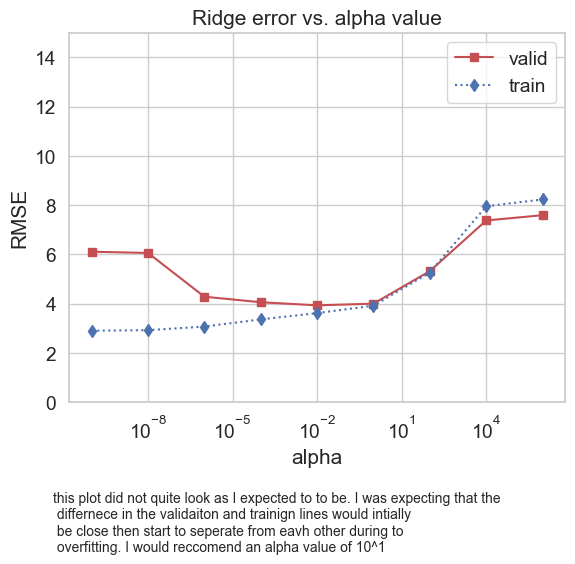

In [82]:
alpha_list = np.asarray([1.e-10, 1.e-08, 1.e-06, 1.e-04, 1.e-02, 1.e+00, 1.e+02, 1.e+04, 1.e+06])
err_tr_alpha = []
err_va_alpha = []

best_val_err_m2 = float('inf')
best_alpha_m2 = None
best_m2_pipeline = None

for i in alpha_list:
    pipe = make_pipeline_ridge_regr_with_poly_feats(degree=4, alpha=i)
    pipe.fit(x_tr_MF, y_tr_M)
    
    tr_err = calc_rmse(y_tr_M, pipe.predict(x_tr_MF))
    va_err = calc_rmse(y_va_N, pipe.predict(x_va_NF))
    
    err_tr_alpha.append(tr_err)
    err_va_alpha.append(va_err)
    
    if va_err < best_val_err_m2:
        best_val_err_m2 = va_err
        best_alpha_m2 = i
        best_m2_pipeline = pipe

err_m2_tr = calc_rmse(y_tr_M, best_m2_pipeline.predict(x_tr_MF))
err_m2_va = calc_rmse(y_va_N, best_m2_pipeline.predict(x_va_NF))
err_m2_te = calc_rmse(y_te_P, best_m2_pipeline.predict(x_te_PF))

plt.figure()
plot_train_and_valid_error_vs_hyper(alpha_list, err_tr_alpha, err_va_alpha, ymax=15, xlabel='alpha')
plt.gca().set_xscale('log')
plt.title('Ridge error vs. alpha value')
plt.figtext(0.1,-0.2, "this plot did not quite look as I expected to to be. I was expecting that the \n differnece in the validaiton and trainign lines would intially \n be close then start to seperate from eavh other during to \n overfitting. I would reccomend an alpha value of 10^1", fontsize = 10)
plt.show()



In [83]:
def make_pipeline_ridge_regr_with_poly_feats_no_scale(degree = 4, alpha = 1.0):
    pipeline = sklearn.pipeline.Pipeline(
        steps=[
        
         ('poly_transformer', sklearn.preprocessing.PolynomialFeatures(degree=degree, include_bias=False)),
         ('regr', sklearn.linear_model.Ridge(alpha=alpha, random_state=SEED))
        ])
    
    # Return the constructed pipeline
    # We can treat it as if it has a 'regression' API
    # e.g. a fit and a predict method
    return pipeline

no_scale_pipe = make_pipeline_ridge_regr_with_poly_feats(degree=4, alpha=i)

no_scale_pipe.fit(x_tr_MF, y_tr_M)
tr_err_no_scale = calc_rmse(y_tr_M, no_scale_pipe.predict(x_tr_MF))


print(f"Sscaled Train RMSE:   {err_tr_alpha[5]:.2f}")
print(f"Unscaled Train RMSE: {tr_err_no_scale:.2f}")

Sscaled Train RMSE:   3.92
Unscaled Train RMSE: 8.23


/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  retur

Quesiton 3:

In [88]:
x_trva_LF = np.vstack([x_tr_MF, x_va_NF])
y_trva_L = np.hstack([y_tr_M, y_va_N])

degree_cv_list = [1, 2, 3, 4, 5, 6, 7]
alpha_cv_list = np.logspace(-10, 6, 17)

kf = sklearn.model_selection.KFold(n_splits=10, shuffle = True, random_state = SEED)

#still need to be inf
best_cv_val_err = float('inf')
best_cv_deg = None


best_cv_alpha = None




print("hello \n")
best_cv_tr_err = None

for deg in degree_cv_list:
    for a in alpha_cv_list:
        fold_tr_errs = []
        fold_va_errs = []
        
        for train_ind, val_ind in kf.split (x_trva_LF, y_trva_L):


            x_fold_tr, x_fold_va = x_trva_LF[train_ind], x_trva_LF[val_ind]
            y_fold_tr, y_fold_va = y_trva_L[train_ind], y_trva_L[val_ind]
            
            pipe = make_pipeline_ridge_regr_with_poly_feats(degree=deg, alpha=a)
            pipe.fit(x_fold_tr, y_fold_tr)
            
            fold_tr_errs.append(calc_rmse(y_fold_tr, pipe.predict(x_fold_tr)))



            fold_va_errs.append(calc_rmse(y_fold_va, pipe.predict(x_fold_va)))
            
        mean_tr_err = np.mean(fold_tr_errs)
        mean_va_err = np.mean(fold_va_errs)
        if mean_va_err < best_cv_val_err:
            best_cv_val_err = mean_va_err
            best_cv_tr_err = mean_tr_err
            best_cv_deg = deg
            best_cv_alpha = a


final_cv_pipeline = make_pipeline_ridge_regr_with_poly_feats(degree=best_cv_deg, alpha=best_cv_alpha)
final_cv_pipeline.fit(x_trva_LF, y_trva_L)
err_m3_te = calc_rmse(y_te_P, final_cv_pipeline.predict(x_te_PF))
            
print("hello \n")          
print(err_m3_te)

hello 



/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/li

hello 

3.8168267610804323


/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/subhangipal/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  retur